<center><h1>Satish_Manvika_HW6</h1></center>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Tree-Based Methods

Import packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score)
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, RocCurveDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 180)
print("Packages imported successfully.")

Packages imported successfully.


### (a) Download the APS Failure data

In [2]:
training_path = Path("../data/aps_failure_training_set.csv")
testing_path = Path("../data/aps_failure_test_set.csv")

aps_train_raw = pd.read_csv(training_path, skiprows=20, na_values="na") #first 20 lines - license information
aps_test_raw = pd.read_csv(testing_path, skiprows=20, na_values="na")
assert aps_train_raw.shape == (60000, 171)
assert aps_test_raw.shape == (16000, 171)
assert aps_train_raw.columns.equals(aps_test_raw.columns)

print("Training-set shape:", aps_train_raw.shape)
print("Testing-set shape:", aps_test_raw.shape)
print("Number of features:", aps_train_raw.shape[1] - 1)
print("\nFirst five training rows:")
display(aps_train_raw.iloc[:5, :9])
print("\nTraining class counts:")
display(aps_train_raw["class"].value_counts().to_frame(name="Count"))
print("\nTesting class counts:")
display(aps_test_raw["class"].value_counts().to_frame(name="Count"))
print("\nMissing values:")
print("Training set:", int(aps_train_raw.isna().sum().sum()))
print("Testing set:", int(aps_test_raw.isna().sum().sum()))

Training-set shape: (60000, 171)
Testing-set shape: (16000, 171)
Number of features: 170

First five training rows:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0



Training class counts:


,Count
class,
neg,59000
pos,1000



Testing class counts:


,Count
class,
neg,15625
pos,375



Missing values:
Training set: 850015
Testing set: 228680


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Several methods can be used to handle missing data:
- **Deletion:** Remove observations or features containing missing values. This can discard substantial information when missingness is common.
- **Simple imputation:** Replace the missing values using a statistic such as mean or median of each feature.
- **K-nearest-neighbor imputation:** Estimate a missing value using observations with similar predictor values.
- **Iterative or multiple imputation:** Predict each incomplete feature using the other available features and account for uncertainty in the imputed values.
- **Model-based handling:** Use a model that can process the missing values internally.

For this analysis, I am going to use median imputation because the predictors are numeric and many of their distributions are highly skewed with large outliers. The median is less sensitive to these extreme values than the mean. To prevent information from the test set from influencing model training, the imputer is fitted using only the training data and then applied to both the training and test predictors.

#### (ii) Calculate the coefficient of variation

In [3]:
X_train_raw = aps_train_raw.drop(columns="class") #sep predictors and encode class labels. neg = 0, pos = 1
X_test_raw = aps_test_raw.drop(columns="class")
y_train = aps_train_raw["class"].map({"neg": 0, "pos": 1})
y_test = aps_test_raw["class"].map({"neg": 0, "pos": 1})
feature_names = X_train_raw.columns.tolist()
assert X_train_raw.shape == (60000, 170)
assert X_test_raw.shape == (16000, 170)
assert y_train.isna().sum() == 0
assert y_test.isna().sum() == 0

median_imputer = SimpleImputer(strategy="median") # fit median imputation using only training data
X_train = pd.DataFrame(median_imputer.fit_transform(X_train_raw), columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(median_imputer.transform(X_test_raw), columns=feature_names, index=X_test_raw.index)
assert X_train.shape == (60000, 170)
assert X_test.shape == (16000, 170)
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Training missing values after imputation:", int(X_train.isna().sum().sum()))
print("Testing missing values after imputation:", int(X_test.isna().sum().sum()))

feature_means = X_train.mean() # calc cv = sample standard deviation / mean for every ft
feature_sample_std = X_train.std(ddof=1)
feature_cv = feature_sample_std / feature_means

cv_table = pd.DataFrame({"Mean": feature_means, "Sample Standard Deviation": feature_sample_std, "CV": feature_cv}).sort_values("CV", ascending=False)
assert cv_table.shape == (170, 3)

print("\nCoefficient of variation calculated for",len(cv_table), "features.")
print("\nTop 20 features by CV:")
display(cv_table.head(20).round(4))

Training missing values after imputation: 0
Testing missing values after imputation: 0

Coefficient of variation calculated for 170 features.

Top 20 features by CV:


,Mean,Sample Standard Deviation,CV
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337
ak_000,907.6607,7.299859e+04,80.4250


#### (iii) Plot a correlation matrix

Correlation matrix shape: (170, 170)


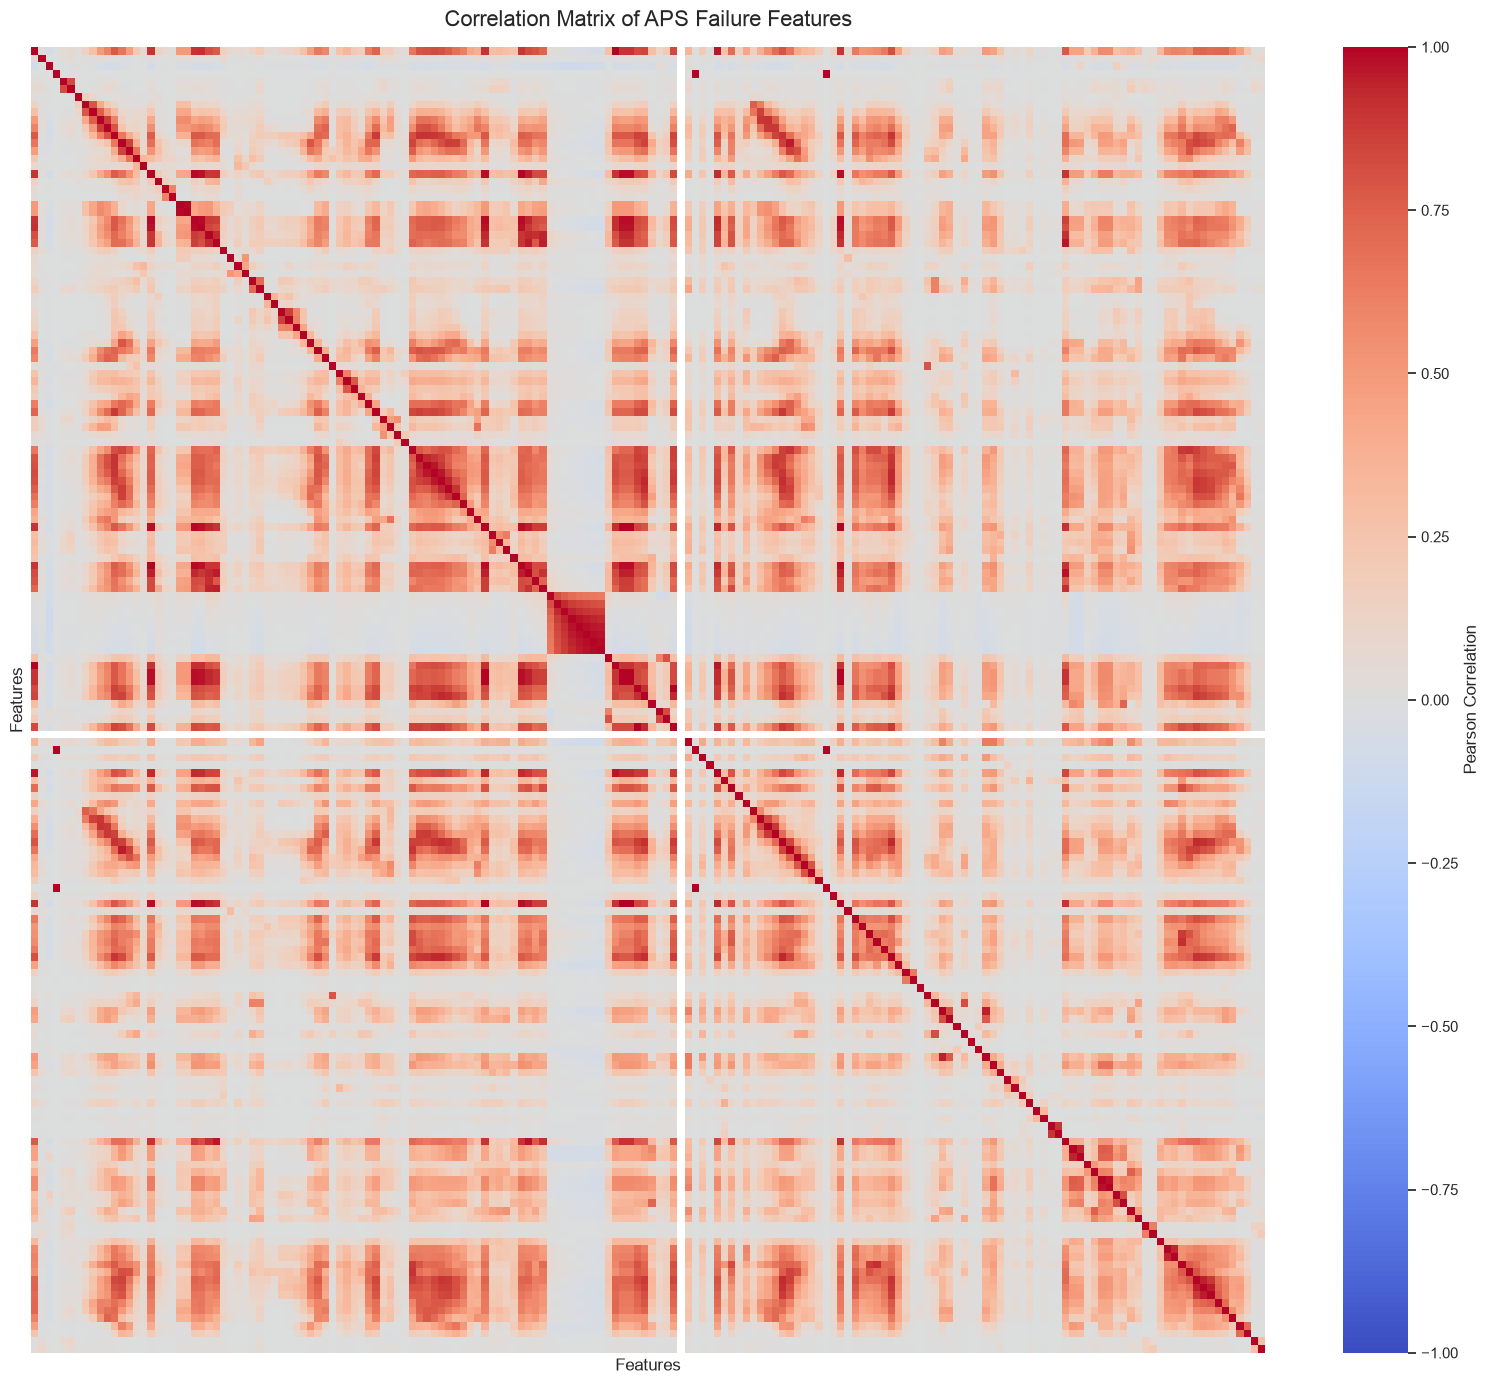

In [4]:
correlation_matrix = X_train.corr() #calc the feature correlation matrix using training set

assert correlation_matrix.shape == (170, 170)
print("Correlation matrix shape:", correlation_matrix.shape)

plt.figure(figsize=(16, 14))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of APS Failure Features", fontsize=16, pad=15)
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Number of selected features: 13
Features with the highest CV:
1. cf_000
2. co_000
3. ad_000
4. cs_009
5. dh_000
6. dj_000
7. ag_000
8. as_000
9. ay_009
10. ak_000
11. az_009
12. ch_000
13. au_000


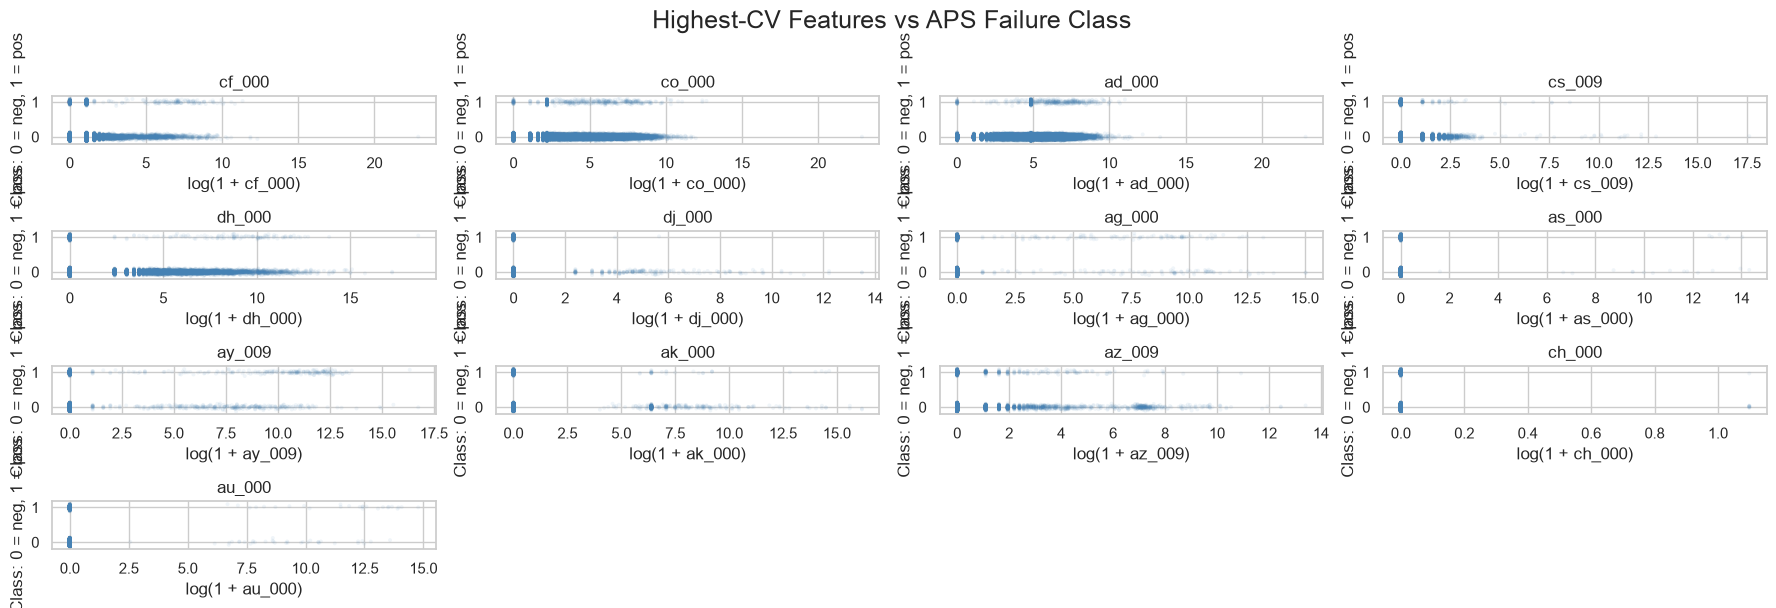

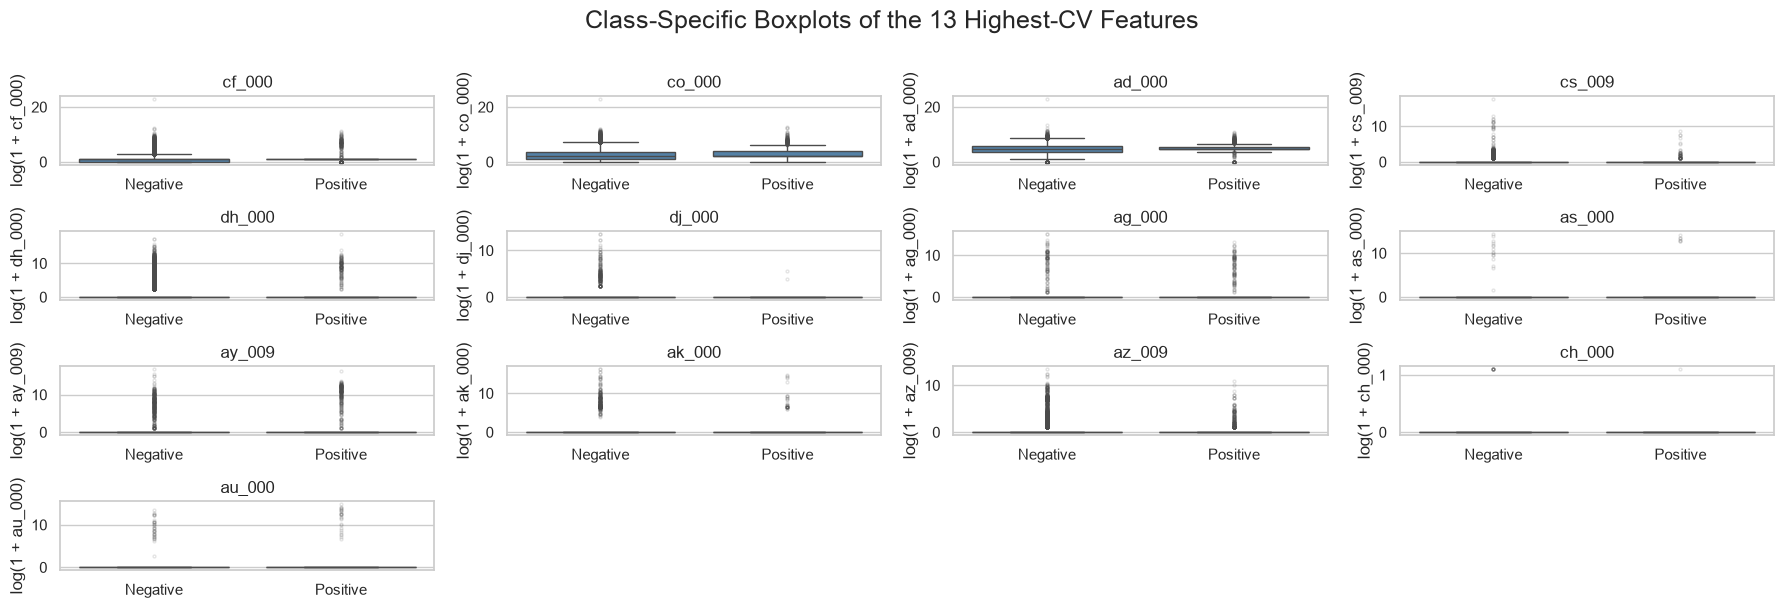

In [5]:
number_of_selected_features = int(np.floor(np.sqrt(170))) #floor(sqrt(170)) - 13 fts with the highest cv
highest_cv_features = cv_table.head(number_of_selected_features).index.tolist()

print("Number of selected features:", number_of_selected_features)
print("Features with the highest CV:")
for number, feature in enumerate(highest_cv_features, start=1):
    print(f"{number}. {feature}")

X_train_log = np.log1p(X_train[highest_cv_features]) #log1p for vis bc the features are skewed

#slight vertical jitter so can see overlapping class values
random_generator = np.random.default_rng(RANDOM_STATE)
jittered_class = (y_train.to_numpy() + random_generator.normal(0, 0.035, len(y_train)))

figure, axes = plt.subplots(4, 4, figsize=(18, 6)) #scatter plots against binary response
axes = axes.flatten()

for axis, feature in zip(axes, highest_cv_features):
    axis.scatter(X_train_log[feature], jittered_class, alpha=0.08, s=8, color="steelblue", edgecolor="none", rasterized=True)
    axis.set_title(feature)
    axis.set_xlabel(f"log(1 + {feature})")
    axis.set_ylabel("Class: 0 = neg, 1 = pos")
    axis.set_yticks([0, 1])

for unused_axis in axes[len(highest_cv_features):]:
    unused_axis.set_visible(False)
    
figure.suptitle("Highest-CV Features vs APS Failure Class", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

plot_data = X_train_log.copy() # class spec boxplots for same features
plot_data["class"] = y_train.map({0: "Negative", 1: "Positive"})

figure, axes = plt.subplots(4, 4, figsize=(18, 6))
axes = axes.flatten()

for axis, feature in zip(axes, highest_cv_features):
    sns.boxplot(data=plot_data, x="class", y=feature, order=["Negative", "Positive"], ax=axis, color="steelblue", showfliers=True, flierprops={"marker": "o", "markersize": 2, "alpha": 0.15})
    axis.set_title(feature)
    axis.set_xlabel("")
    axis.set_ylabel(f"log(1 + {feature})")

for unused_axis in axes[len(highest_cv_features):]:
    unused_axis.set_visible(False)

figure.suptitle("Class-Specific Boxplots of the 13 Highest-CV Features", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

#### Highest-CV Feature Interpretation
The 13 predictors with the highest coefficients of variation show substantial variability relative to their means. Several features, including `cs_009`, `dh_000`, `dj_000`, `ag_000`, `as_000`, `ay_009`, `ak_000`, `az_009`, and `au_000`, are highly zero-inflated. That means their large CV values are driven partly by small means and a relatively small number of large nonzero observations. The plots show that some features, such as `cf_000`, `co_000`, and `ad_000`, have different distributions between the positive and negative classes. But, there is also considerable overlap between the classes, and the number of positive observations is a lot smaller than the number of negative observations. Statistical significance can't be established from scatter plots or boxplots by themselves. These plots are useful for identifying possible patterns, skewness, outliers, and class differences, but formal statistical tests or predictive modeling would be needed to determine whether the features give us significant information after accounting for the other predictors.

#### (v) Is this data set imbalanced?

APS failure class distribution:


,Training Count,Training Percentage,Testing Count,Testing Percentage
Negative,59000,98.3333,15625,97.6562
Positive,1000,1.6667,375,2.3438


Training negative-to-positive ratio: 59.00:1
Testing negative-to-positive ratio: 41.67:1


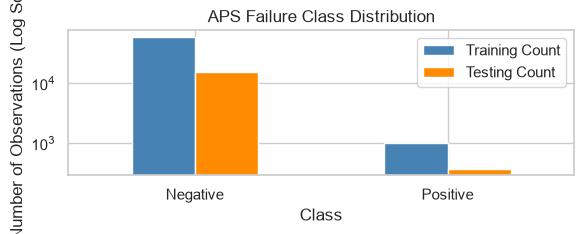

In [6]:
training_class_counts = y_train.value_counts().sort_index() #count pos and neg observations
testing_class_counts = y_test.value_counts().sort_index()
class_balance_table = pd.DataFrame({"Training Count": training_class_counts, "Training Percentage": (training_class_counts / len(y_train) * 100), "Testing Count": testing_class_counts, "Testing Percentage": (testing_class_counts / len(y_test) * 100)})
class_balance_table.index = ["Negative", "Positive"]
print("APS failure class distribution:")
display(class_balance_table.round(4))

training_imbalance_ratio = (training_class_counts[0] / training_class_counts[1])
testing_imbalance_ratio = (testing_class_counts[0] / testing_class_counts[1])
print("Training negative-to-positive ratio:", f"{training_imbalance_ratio:.2f}:1")
print("Testing negative-to-positive ratio:", f"{testing_imbalance_ratio:.2f}:1")

# Plot class counts on a logarithmic scale
class_balance_table[["Training Count", "Testing Count"]].plot(kind="bar", figsize=(6, 2.5), color=["steelblue", "darkorange"])
plt.yscale("log")
plt.ylabel("Number of Observations (Log Scale)")
plt.xlabel("Class")
plt.title("APS Failure Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The dataset is severely imbalanced because the negative class greatly outnumbers the positive class

### (c) Train a random forest

Uncompensated random forest results:


,TN,FP,FN,TP,Misclassification Rate,AUC
Training,59000,0,0,1000,0.000000,1.000000
Testing,15608,17,106,269,0.007687,0.994449


OOB error estimate: 0.005683
Test misclassification rate: 0.007687
Difference between OOB and test error: 0.002004


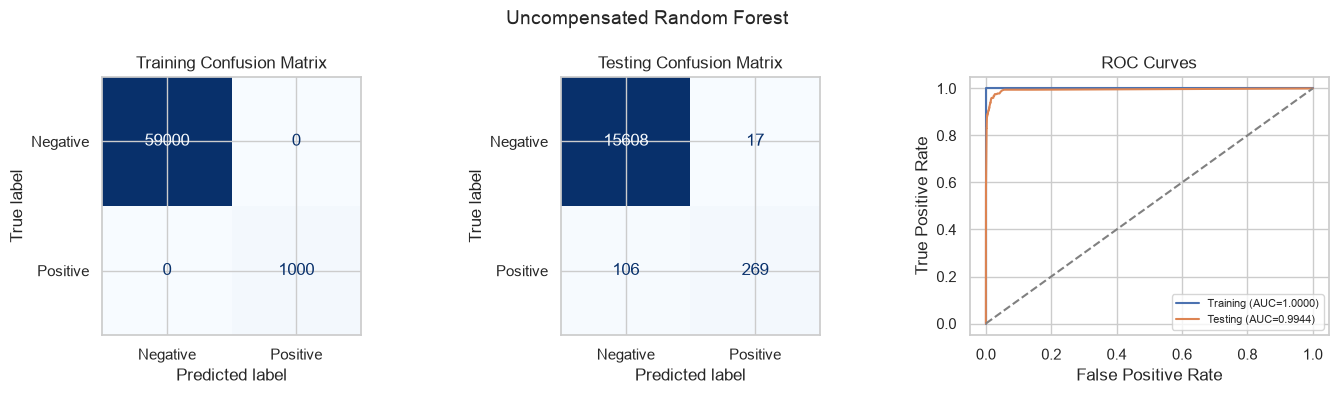

In [7]:
# Helper function for classification performance
def classification_metrics(y_true, predictions, probabilities):
    confusion = confusion_matrix(y_true, predictions, labels=[0, 1])
    return {"TN": confusion[0, 0], "FP": confusion[0, 1], "FN": confusion[1, 0], "TP": confusion[1, 1], "Misclassification Rate": (1 - accuracy_score(y_true, predictions)), "AUC": roc_auc_score(y_true, probabilities)}

def plot_model_diagnostics(model_name, y_train, train_predictions, train_probabilities, y_test, test_predictions, test_probabilities, alpha_results=None, selected_alpha=None):
    include_alpha = alpha_results is not None
    number_of_columns = 4 if include_alpha else 3
    figure, axes = plt.subplots(1, number_of_columns, figsize=(18 if include_alpha else 14, 4))
    plot_position = 0
    if include_alpha:
        alpha_values = (alpha_results["reg_alpha"].astype(float).replace(0, 0.0001))
        axes[0].semilogx(alpha_values, alpha_results["Mean CV AUC"], marker="o")
        axes[0].axvline(max(float(selected_alpha), 0.0001), color="red", linestyle="--")
        axes[0].set_title("L1 Selection")
        axes[0].set_xlabel("reg_alpha")
        axes[0].set_ylabel("Mean CV AUC")
        plot_position = 1

    ConfusionMatrixDisplay.from_predictions(y_train,train_predictions,display_labels=["Negative", "Positive"],cmap="Blues",colorbar=False,ax=axes[plot_position])
    axes[plot_position].set_title("Training Confusion Matrix")
    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, display_labels=["Negative", "Positive"],cmap="Blues", colorbar=False, ax=axes[plot_position + 1])
    axes[plot_position + 1].set_title("Testing Confusion Matrix")
    train_fpr, train_tpr, _ = roc_curve(y_train, train_probabilities)
    test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities)
    roc_axis = axes[plot_position + 2]
    roc_axis.plot(train_fpr, train_tpr,
        label=(
            "Training "
            f"(AUC={roc_auc_score(y_train, train_probabilities):.4f})"
        )
    )
    roc_axis.plot(test_fpr, test_tpr,
        label=(
            "Testing "
            f"(AUC={roc_auc_score(y_test, test_probabilities):.4f})"
        )
    )
    roc_axis.plot([0, 1], [0, 1], color="gray", linestyle="--")
    roc_axis.set_title("ROC Curves")
    roc_axis.set_xlabel("False Positive Rate")
    roc_axis.set_ylabel("True Positive Rate")
    roc_axis.legend(fontsize=8)
    figure.suptitle(model_name, fontsize=14)
    plt.tight_layout()
    plt.show()
    
#uncompensated random forest
uncompensated_rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", bootstrap=True, oob_score=True, class_weight=None, random_state=RANDOM_STATE, n_jobs=-1)
uncompensated_rf.fit(X_train, y_train)

rf_train_predictions = uncompensated_rf.predict(X_train) # preds and pos-class probs
rf_test_predictions = uncompensated_rf.predict(X_test)
rf_train_probabilities = (uncompensated_rf.predict_proba(X_train)[:, 1])
rf_test_probabilities = (uncompensated_rf.predict_proba(X_test)[:, 1])

#performance meausers
rf_train_metrics = classification_metrics(y_train, rf_train_predictions, rf_train_probabilities)
rf_test_metrics = classification_metrics(y_test, rf_test_predictions, rf_test_probabilities)
rf_results = pd.DataFrame([rf_train_metrics, rf_test_metrics], index=["Training", "Testing"])
print("Uncompensated random forest results:")
display(rf_results.round(6))
rf_oob_error = 1 - uncompensated_rf.oob_score_
rf_test_error = rf_test_metrics["Misclassification Rate"]

print("OOB error estimate:", round(rf_oob_error, 6))
print("Test misclassification rate:", round(rf_test_error, 6))
print("Difference between OOB and test error:", round(abs(rf_oob_error - rf_test_error), 6))
plot_model_diagnostics("Uncompensated Random Forest", y_train, rf_train_predictions, rf_train_probabilities, y_test, rf_test_predictions, rf_test_probabilities)

#### Uncompensated Random Forest Interpretation
The uncompensated random forest perfectly classified the training data, which is expected for a flexible ensemble of fully grown trees. On the test set, it output 17 false positives and 106 false negatives, with a misclassification rate of 0.007687 and an AUC of 0.994449. The out-of-bag error estimate was 0.005683, which is close to the test error of 0.007687. This shows that the OOB estimate gives us a reasonable approximation of the model's test performance. Although the overall test error is low, it should be interpreted with caution because the negative class dominates the dataset. The model correctly identified only 269 of the 375 positive observations, giving a positive-class recall of approximately 71.7%. So, the overall accuracy alone hides a meaningful number of missed APS failures.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be addressed using several methods:
- **Class weighting:** Assign a larger penalty to mistakes on the minority class.
- **Balanced bootstrap sampling:** Draw approximately equal numbers of observations from each class for each tree.
- **Oversampling:** Duplicate or synthetically generate minority-class observations.
- **Undersampling:** Reduce the number of majority-class observations.
- **Threshold adjustment:** Lower the probability threshold required to predict the minority class.
  
For this analysis, I am using class weighting through `class_weight="balanced_subsample"`. Each tree computes class weights from its bootstrap sample, giving greater importance to positive APS failures without changing the original training observations.

Class-weighted random forest results:


,TN,FP,FN,TP,Misclassification Rate,AUC
Training,59000,0,0,1000,0.000000,1.000000
Testing,15610,15,156,219,0.010687,0.993314


OOB error estimate: 0.007617
Test misclassification rate: 0.010687

Random forest comparison:


,Model,Test Misclassification Rate,Test AUC,False Positives,False Negatives,Positive Recall
0,Uncompensated Random Forest,0.007687,0.994449,17,106,0.717333
1,Class-Weighted Random Forest,0.010687,0.993314,15,156,0.584000


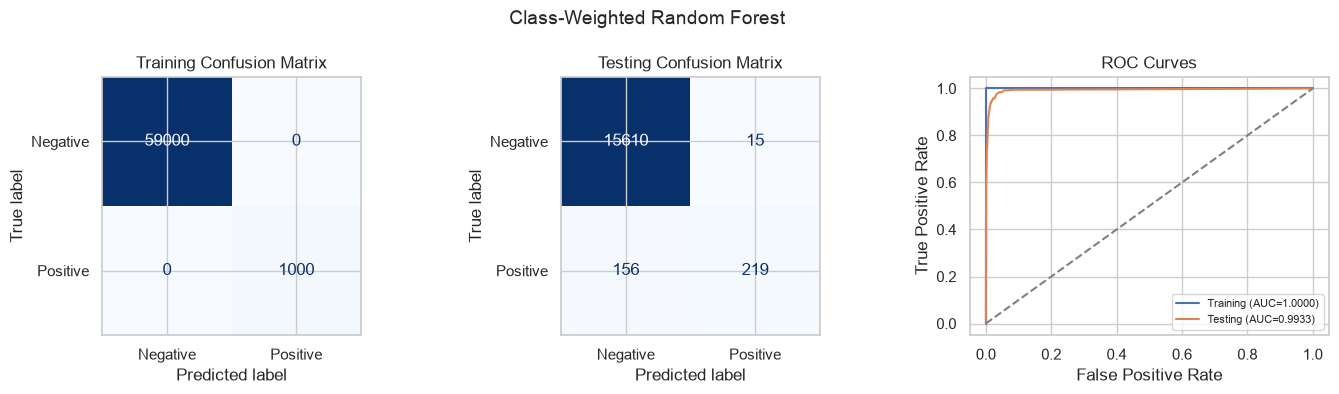

In [8]:
#class weighted random forest
compensated_rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", bootstrap=True, oob_score=True, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
compensated_rf.fit(X_train, y_train)
balanced_rf_train_predictions = (compensated_rf.predict(X_train)) # preds and probs
balanced_rf_test_predictions = (compensated_rf.predict(X_test))
balanced_rf_train_probabilities = (compensated_rf.predict_proba(X_train)[:, 1])
balanced_rf_test_probabilities = (compensated_rf.predict_proba(X_test)[:, 1])

#performance metrics
balanced_rf_train_metrics = (classification_metrics(y_train, balanced_rf_train_predictions, balanced_rf_train_probabilities))
balanced_rf_test_metrics = (classification_metrics(y_test, balanced_rf_test_predictions, balanced_rf_test_probabilities))
balanced_rf_results = pd.DataFrame([balanced_rf_train_metrics, balanced_rf_test_metrics], index=["Training", "Testing"])

print("Class-weighted random forest results:")
display(balanced_rf_results.round(6))
balanced_rf_oob_error = (1 - compensated_rf.oob_score_)
balanced_rf_test_error = (balanced_rf_test_metrics["Misclassification Rate"])
print("OOB error estimate:", round(balanced_rf_oob_error, 6))
print("Test misclassification rate:", round(balanced_rf_test_error, 6))

#compare the 2 random forests
rf_comparison = pd.DataFrame({
    "Model": ["Uncompensated Random Forest", "Class-Weighted Random Forest"],
    "Test Misclassification Rate": [rf_test_metrics["Misclassification Rate"], balanced_rf_test_metrics["Misclassification Rate"]],
    "Test AUC": [rf_test_metrics["AUC"], balanced_rf_test_metrics["AUC"]],
    "False Positives": [rf_test_metrics["FP"], balanced_rf_test_metrics["FP"]],
    "False Negatives": [rf_test_metrics["FN"], balanced_rf_test_metrics["FN"]],
    "Positive Recall": [rf_test_metrics["TP"] / (rf_test_metrics["TP"] + rf_test_metrics["FN"]), balanced_rf_test_metrics["TP"] / (balanced_rf_test_metrics["TP"] + balanced_rf_test_metrics["FN"])]
})

print("\nRandom forest comparison:")
display(rf_comparison.round(6))
plot_model_diagnostics("Class-Weighted Random Forest", y_train, balanced_rf_train_predictions, balanced_rf_train_probabilities, y_test, balanced_rf_test_predictions, balanced_rf_test_probabilities)

#### Class-Weighted Random Forest Interpretation

Class weighting didn't improve performance for this random forest configuration. The class-weighted model produced a higher test misclassification rate (0.010687 versus 0.007687), a slightly lower AUC (0.993314 versus 0.994449), and more false negatives (156 versus 106). Positive-class recall decreased from approximately 71.7% to 58.4%. Therefore, `class_weight="balanced_subsample"` didn't improve minority-class detection in this case. This result shows that class weighting changes how the trees are constructed but doesn't guarantee better performance at the default 0.5 classification threshold. Other approaches like SMOTE, balanced sampling, or threshold tuning, may produce a different tradeoff between false positives and false negatives.

### (e) XGBoost and Model Trees

XGBoost alpha cross-validation results:


,reg_alpha,Mean CV AUC,CV AUC Standard Deviation
0,0.000,0.990245,0.003671
1,0.001,0.990247,0.003662
2,0.010,0.990349,0.003521
3,0.100,0.989979,0.003431
4,1.000,0.990239,0.003899
5,10.000,0.989490,0.003958
6,100.000,0.982859,0.003853


Selected XGBoost alpha: 0.01

Uncompensated XGBoost results:


,TN,FP,FN,TP,Misclassification Rate,AUC
Training,58977,23,147,853,0.002833,0.998408
Testing,15607,18,91,284,0.006812,0.996416


Five-fold CV error estimate: 0.006317
Five-fold CV AUC: 0.990027
Test misclassification rate: 0.006812
Test AUC: 0.996416


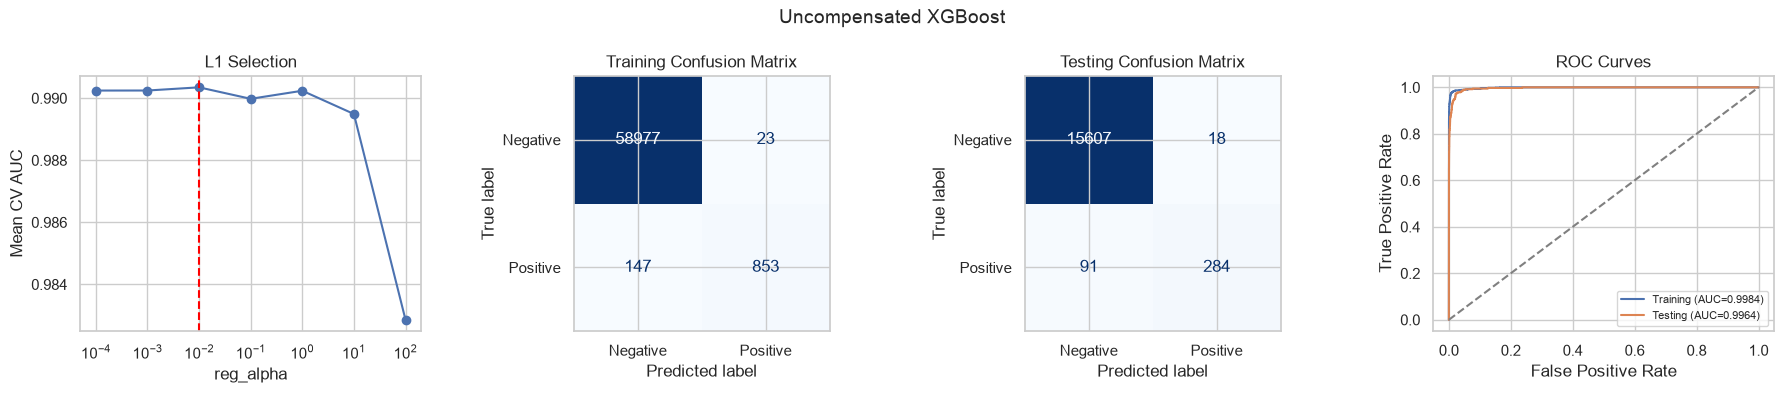

In [9]:
from sklearn.model_selection import cross_val_predict

xgboost_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE) #5-fold stratified cross-validation
xgboost_alpha_values = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0] # candidate l1 reg strengths

# std xgboost w/o class-imbalance comp
uncompensated_xgboost = XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)

# select reg_alpha using five-fold cv
xgboost_search = GridSearchCV(estimator=uncompensated_xgboost, param_grid={"reg_alpha": xgboost_alpha_values}, scoring="roc_auc", cv=xgboost_cv, n_jobs=-1, return_train_score=False)
xgboost_search.fit(X_train, y_train)
xgboost_cv_results = pd.DataFrame({"reg_alpha": xgboost_alpha_values, "Mean CV AUC": xgboost_search.cv_results_["mean_test_score"], "CV AUC Standard Deviation": xgboost_search.cv_results_["std_test_score"]})
print("XGBoost alpha cross-validation results:")
display(xgboost_cv_results.round(6))
selected_xgboost_alpha = (xgboost_search.best_params_["reg_alpha"])
best_xgboost = xgboost_search.best_estimator_
print("Selected XGBoost alpha:", selected_xgboost_alpha)

#oof probabilities est cv performance
xgboost_cv_probabilities = cross_val_predict(best_xgboost, X_train, y_train, cv=xgboost_cv, method="predict_proba", n_jobs=-1)[:, 1]

xgboost_cv_predictions = (xgboost_cv_probabilities >= 0.5).astype(int)
xgboost_cv_error = (1 - accuracy_score(y_train, xgboost_cv_predictions))
xgboost_cv_auc = roc_auc_score(y_train, xgboost_cv_probabilities)

# Training and testing predictions
xgboost_train_predictions = (best_xgboost.predict(X_train))
xgboost_test_predictions = (best_xgboost.predict(X_test))
xgboost_train_probabilities = (best_xgboost.predict_proba(X_train)[:, 1])
xgboost_test_probabilities = (best_xgboost.predict_proba(X_test)[:, 1])
xgboost_train_metrics = classification_metrics(y_train, xgboost_train_predictions, xgboost_train_probabilities)
xgboost_test_metrics = classification_metrics(y_test, xgboost_test_predictions, xgboost_test_probabilities)
xgboost_results = pd.DataFrame([xgboost_train_metrics, xgboost_test_metrics], index=["Training", "Testing"])
print("\nUncompensated XGBoost results:")
display(xgboost_results.round(6))

print("Five-fold CV error estimate:", round(xgboost_cv_error, 6))
print("Five-fold CV AUC:", round(xgboost_cv_auc, 6))
print("Test misclassification rate:", round(xgboost_test_metrics["Misclassification Rate"], 6))
print("Test AUC:", round(xgboost_test_metrics["AUC"], 6))
plot_model_diagnostics("Uncompensated XGBoost", y_train, xgboost_train_predictions, xgboost_train_probabilities, y_test, xgboost_test_predictions, xgboost_test_probabilities, alpha_results=xgboost_cv_results, selected_alpha=selected_xgboost_alpha)

#### Uncompensated XGBoost Interpretation
Five-fold cross-validation chose an L1 regularization strength of $\alpha=0.01$. The out-of-fold cross-validation error was 0.006317, which is close to the test misclassification rate of 0.006812. The similarity between these values shows that cross-validation gives us a reliable estimate of test performance. The test confusion matrix had 18 false positives and 91 false negatives. The model correctly identified 284 of the 375 positive test observations, giving a positive-class recall of approximately 75.7%. Its test AUC of 0.996416 shows excellent discrimination between positive and negative observations. Compared with the uncompensated random forest, XGBoost got a lower test error, a higher test AUC, fewer false negatives, and higher positive-class recall. However, the 91 missed positive cases show that the severe class imbalance still affects predictions at the default probability threshold.

### (f) Use SMOTE to pre-process your data

Fitting 5 folds for each of 7 candidates, totalling 35 fits
SMOTE-XGBoost alpha CV results:


,reg_alpha,Mean CV AUC,CV AUC Standard Deviation
0,0.000,0.987135,0.004548
1,0.001,0.987164,0.004525
2,0.010,0.987293,0.004417
3,0.100,0.986848,0.004808
4,1.000,0.987363,0.004488
5,10.000,0.987290,0.004497
6,100.000,0.986784,0.003692


Selected SMOTE-XGBoost alpha: 1.0

SMOTE-XGBoost results:


,TN,FP,FN,TP,Misclassification Rate,AUC
Training,58180,820,47,953,0.014450,0.996633
Testing,15397,228,31,344,0.016188,0.993886


Five-fold CV error estimate: 0.016383
Five-fold CV AUC: 0.986854
Test misclassification rate: 0.016188
Test AUC: 0.993886

XGBoost model comparison:


,Model,Selected Alpha,CV Error,Test Error,Test AUC,False Positives,False Negatives,Positive Recall
0,Uncompensated XGBoost,0.01,0.006317,0.006812,0.996416,18,91,0.757333
1,SMOTE-XGBoost,1.00,0.016383,0.016188,0.993886,228,31,0.917333


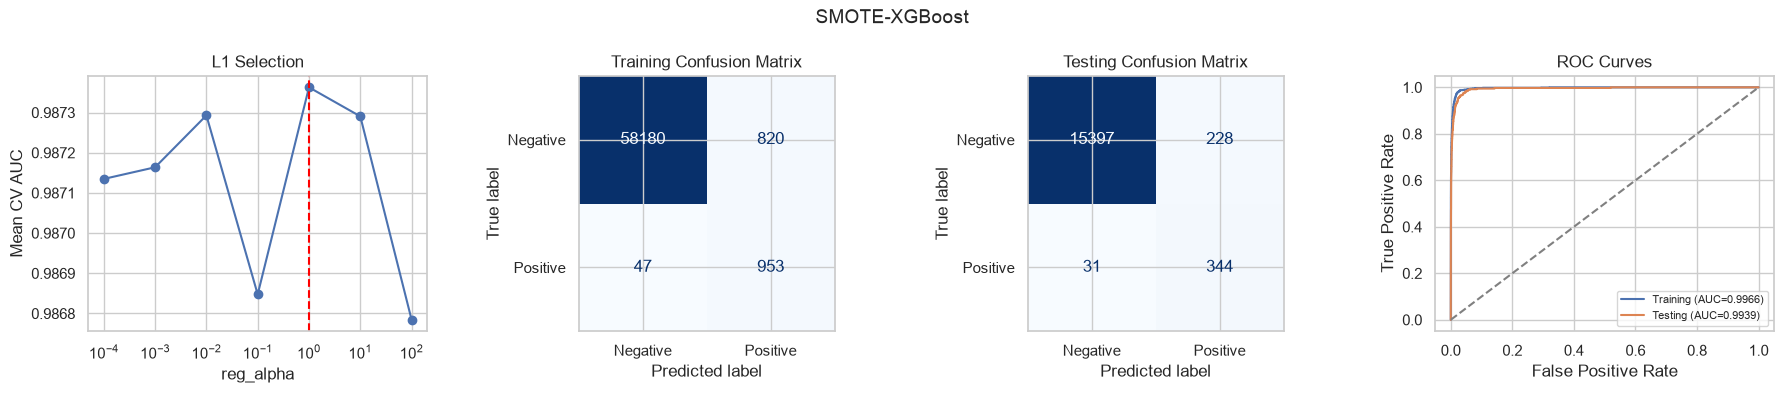

In [10]:
from sklearn.preprocessing import StandardScaler

# scaling included bc smote uses nn distances
smote_xgboost = ImbalancedPipeline(steps=[("scaler", StandardScaler()), ("smote", SMOTE(sampling_strategy="auto", random_state=RANDOM_STATE, k_neighbors=5)), ("xgboost", XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1))])

# tune L1 reg with smote performed inside each fold
smote_xgboost_search = GridSearchCV(estimator=smote_xgboost, param_grid={"xgboost__reg_alpha": xgboost_alpha_values}, scoring="roc_auc", cv=xgboost_cv, n_jobs=1, return_train_score=False, verbose=1)
smote_xgboost_search.fit(X_train, y_train)
smote_cv_results = pd.DataFrame({"reg_alpha": xgboost_alpha_values, "Mean CV AUC": smote_xgboost_search.cv_results_["mean_test_score"], "CV AUC Standard Deviation": smote_xgboost_search.cv_results_["std_test_score"]})
print("SMOTE-XGBoost alpha CV results:")
display(smote_cv_results.round(6))

selected_smote_alpha = (smote_xgboost_search.best_params_["xgboost__reg_alpha"])
best_smote_xgboost = (smote_xgboost_search.best_estimator_)
print("Selected SMOTE-XGBoost alpha:", selected_smote_alpha)

# correct oof predictions, smote is applied separately inside each training fold
smote_cv_probabilities = cross_val_predict(best_smote_xgboost, X_train, y_train, cv=xgboost_cv, method="predict_proba", n_jobs=1)[:, 1]
smote_cv_predictions = (smote_cv_probabilities >= 0.5).astype(int)
smote_cv_error = (1 - accuracy_score(y_train, smote_cv_predictions))
smote_cv_auc = roc_auc_score(y_train, smote_cv_probabilities)
smote_train_predictions = (best_smote_xgboost.predict(X_train)) # eval final fitted pipeline
smote_test_predictions = (best_smote_xgboost.predict(X_test))
smote_train_probabilities = (best_smote_xgboost.predict_proba(X_train)[:, 1])
smote_test_probabilities = (best_smote_xgboost.predict_proba(X_test)[:, 1])
smote_train_metrics = classification_metrics(y_train, smote_train_predictions, smote_train_probabilities)
smote_test_metrics = classification_metrics(y_test, smote_test_predictions, smote_test_probabilities)
smote_results = pd.DataFrame([smote_train_metrics, smote_test_metrics], index=["Training", "Testing"])

print("\nSMOTE-XGBoost results:")
display(smote_results.round(6))
print("Five-fold CV error estimate:", round(smote_cv_error, 6))
print("Five-fold CV AUC:", round(smote_cv_auc, 6))
print("Test misclassification rate:", round(smote_test_metrics["Misclassification Rate"], 6))
print("Test AUC:", round(smote_test_metrics["AUC"], 6))

# comp uncompensated and smote models
xgboost_comparison = pd.DataFrame({
    "Model": ["Uncompensated XGBoost", "SMOTE-XGBoost"],
    "Selected Alpha": [selected_xgboost_alpha, selected_smote_alpha],
    "CV Error": [xgboost_cv_error, smote_cv_error],
    "Test Error": [xgboost_test_metrics["Misclassification Rate"], smote_test_metrics["Misclassification Rate"]],
    "Test AUC": [xgboost_test_metrics["AUC"], smote_test_metrics["AUC"]],
    "False Positives": [xgboost_test_metrics["FP"], smote_test_metrics["FP"]],
    "False Negatives": [xgboost_test_metrics["FN"], smote_test_metrics["FN"]],
    "Positive Recall": [xgboost_test_metrics["TP"] / (xgboost_test_metrics["TP"] + xgboost_test_metrics["FN"]), smote_test_metrics["TP"] / (smote_test_metrics["TP"] + smote_test_metrics["FN"])]
})

print("\nXGBoost model comparison:")
display(xgboost_comparison.round(6))
plot_model_diagnostics("SMOTE-XGBoost", y_train, smote_train_predictions, smote_train_probabilities, y_test, smote_test_predictions, smote_test_probabilities, alpha_results=smote_cv_results, selected_alpha=selected_smote_alpha)

#### SMOTE-XGBoost Interpretation

SMOTE was applied inside each cross-validation training fold, which prevents synthetic observations from leaking into the corresponding validation fold. Cross-validation selected an L1 regularization strength of $\alpha=1.0$. The cross-validation error of 0.016383 was close to the test error of 0.016188. Compared with uncompensated XGBoost, SMOTE increased positive-class recall from approximately 75.7% to 91.7% and reduced false negatives from 91 to 31. This improvement came at the cost of increasing false positives from 18 to 228, increasing the overall test error, and slightly reducing test AUC. The APS dataset assigns a cost of 10 to each false positive and 500 to each false negative. So:
- Uncompensated XGBoost cost: $18(10)+91(500)=45{,}680$
- SMOTE-XGBoost cost: $228(10)+31(500)=17{,}780$

Although SMOTE-XGBoost has a higher overall misclassification rate, it is preferable under the APS cost structure because missing an actual APS failure is far more expensive than performing an unnecessary inspection.

## 2. ISLR 6.6.3

The constraint
$$
\sum_{j=1}^{p}|\beta_j|\leq s
$$
controls the flexibility of the lasso model. When $s=0$, all slope coefficients must equal zero. As $s$ increases, the constraint becomes less restrictive and the model becomes more flexible.

#### (a) Training RSS
**Answer: iv. Steadily decrease.**
As $s$ increases, the feasible set of coefficient values becomes larger. Every model available for a smaller value of $s$ is also available for a larger value so the minimum training RSS can't increase. It decreases, or remains unchanged, until the lasso solution reaches the unrestricted least-squares solution.
#### (b) Test RSS
**Answer: ii. Decrease initially, and then eventually start increasing in a U shape.**
For very small $s$, the model is highly constrained and may underfit, producing a high test error. Increasing $s$ initially reduces bias and improves test performance. If $s$ becomes too large, the model becomes more flexible and its variance increases, which may lead to overfitting so the test RSS generally follows a U-shaped pattern.
#### (c) Variance
**Answer: iii. Steadily increase.**
As $s$ increases, the coefficient constraint becomes weaker and the fitted model becomes more sensitive to changes in the training data so the variance generally increases.
#### (d) Squared Bias
**Answer: iv. Steadily decrease.**
A small value of $s$ strongly shrinks the coefficients toward zero and creates a relatively inflexible model with high bias. As $s$ increases, the model becomes more flexible and can better approximate the underlying relationship, so squared bias generally decreases.
#### (e) Irreducible Error
**Answer: v. Remain constant.**
Irreducible error is caused by random noise in the data-generating process. It doesn't depend on the model or the value of $s$, so it stays constant.

## 3. ISLR 6.6.5

Because the predictors are identical,
$$
x_{11}=x_{12}
\qquad\text{and}\qquad
x_{21}=x_{22},
$$
and the variables and response are centered, the intercept estimate is
$$
\hat{\beta}_0=0.
$$

#### (a) Ridge Regression Optimization Problem
The ridge regression coefficients minimize
$$
\begin{aligned}
&\left(y_1-\beta_1x_{11}-\beta_2x_{12}\right)^2
+\left(y_2-\beta_1x_{21}-\beta_2x_{22}\right)^2 \\
&\qquad+\lambda\left(\beta_1^2+\beta_2^2\right).
\end{aligned}
$$

Because $x_{11}=x_{12}$ and $x_{21}=x_{22}$, this can be rewritten as
$$
\left[y_1-x_{11}(\beta_1+\beta_2)\right]^2
+\left[y_2-x_{21}(\beta_1+\beta_2)\right]^2
+\lambda\left(\beta_1^2+\beta_2^2\right).
$$

#### (b) Show That the Ridge Coefficients Are Equal
The residual sum of squares depends on the coefficients only through the sum
$$
\beta_1+\beta_2.
$$

For any fixed value of this sum, the ridge penalty can be written as

$$
\beta_1^2+\beta_2^2
=
\frac{(\beta_1+\beta_2)^2}{2}
+
\frac{(\beta_1-\beta_2)^2}{2}.
$$

The first term is constant when $\beta_1+\beta_2$ is fixed. The second term is minimized when
$$
\beta_1-\beta_2=0.
$$

Therefore,
$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}.
$$

Thus, ridge regression gives identical coefficient estimates to the two identical predictors.

#### (c) Lasso Optimization Problem
The lasso coefficients minimize
$$
\begin{aligned}
&\left(y_1-\beta_1x_{11}-\beta_2x_{12}\right)^2
+\left(y_2-\beta_1x_{21}-\beta_2x_{22}\right)^2 \\
&\qquad+\lambda\left(|\beta_1|+|\beta_2|\right).
\end{aligned}
$$

Using the fact that the predictors are identical, this becomes
$$
\left[y_1-x_{11}(\beta_1+\beta_2)\right]^2
+\left[y_2-x_{21}(\beta_1+\beta_2)\right]^2
+\lambda\left(|\beta_1|+|\beta_2|\right).
$$

#### (d) Show That the Lasso Coefficients Are Not Unique
Let
$$
\theta=\beta_1+\beta_2.
$$

The fitted values and residual sum of squares depend only on $\theta$. Suppose the optimal combined coefficient is $\hat{\theta}$. Any same-sign pair satisfying
$$
\beta_1+\beta_2=\hat{\theta}
$$
produces the same fitted values and the same lasso penalty because

$$
|\beta_1|+|\beta_2|
=
|\beta_1+\beta_2|
=
|\hat{\theta}|.
$$

If $\hat{\theta}>0$, all pairs of the form
$$
\beta_1=t,
\qquad
\beta_2=\hat{\theta}-t,
\qquad
0\leq t\leq\hat{\theta}
$$
are solutions.

If $\hat{\theta}<0$, all pairs of the form
$$
\beta_1=t,
\qquad
\beta_2=\hat{\theta}-t,
\qquad
\hat{\theta}\leq t\leq0
$$
are solutions. Therefore, the lasso can distribute the combined coefficient between the two identical predictors in infinitely many ways. The individual coefficient estimates aren't unique, but their sum and the fitted values are unique.

## 4. ISLR 8.4.5

The ten estimated probabilities that the observation belongs to the red class are
$$
0.10,\ 0.15,\ 0.20,\ 0.20,\ 0.55,\ 0.60,\ 0.60,\ 0.65,\ 0.70,\ 0.75.
$$
#### Majority Vote
Each tree predicts red when its estimated probability is greater than $0.5$ and green otherwise. The first four trees predict green:
$$
0.10,\ 0.15,\ 0.20,\ 0.20.
$$
The remaining six trees predict red:
$$
0.55,\ 0.60,\ 0.60,\ 0.65,\ 0.70,\ 0.75.
$$
Therefore, six trees vote for red and four vote for green. Under the majority-vote approach, the final classification is
$$
\boxed{\text{Red}}.
$$
#### Average Probability
The average estimated probability of belonging to the red class is
$$
\begin{aligned}
\bar{p}
&=
\frac{
0.10+0.15+0.20+0.20+0.55+
0.60+0.60+0.65+0.70+0.75
}{10} \\
&=
\frac{4.50}{10} \\
&=
0.45.
\end{aligned}
$$
Because $0.45<0.5$, the average-probability approach classifies the observation as
$$
\boxed{\text{Green}}.
$$
Thus, the two approaches produce different classifications:
- **Majority vote:** Red
- **Average probability:** Green

## 5. ISLR 9.7.3

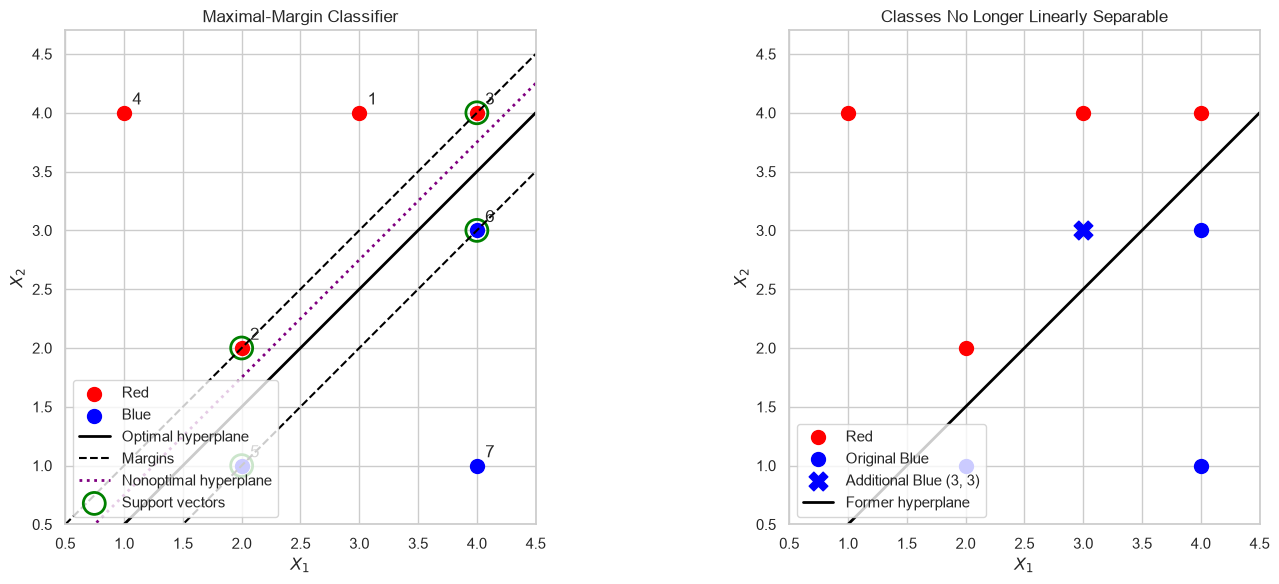

In [11]:
red_points = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue_points = np.array([[2, 1], [4, 3], [4, 1]])
observation_numbers = np.arange(1, 8)
x_values = np.linspace(0.5, 4.5, 300)
figure, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(red_points[:, 0], red_points[:, 1], color="red", s=100, label="Red") # og obs and separating hyperplanes
axes[0].scatter(blue_points[:, 0], blue_points[:, 1], color="blue", s=100, label="Blue")
all_points = np.vstack([red_points, blue_points])
for number, point in zip(observation_numbers, all_points):
    axes[0].annotate(str(number), (point[0], point[1]), xytext=(6, 6), textcoords="offset points")

axes[0].plot(x_values, x_values - 0.5, color="black", linewidth=2, label="Optimal hyperplane") #optimal hyperplane: x2 = x1 - 0.5
axes[0].plot(x_values, x_values, color="black", linestyle="--", label="Margins") # margin boundaries
axes[0].plot(x_values, x_values - 1, color="black", linestyle="--")
axes[0].plot(x_values, x_values - 0.25, color="purple", linestyle=":", linewidth=2, label="Nonoptimal hyperplane") # ex nonoptimal separating hyperplane
support_vectors = np.array([[2, 2], [4, 4], [2, 1], [4, 3]]) # circle support vectors
axes[0].scatter(support_vectors[:, 0], support_vectors[:, 1], facecolors="none", edgecolors="green", s=250, linewidths=2, label="Support vectors")
axes[0].set_title("Maximal-Margin Classifier")
axes[0].set_xlabel("$X_1$")
axes[0].set_ylabel("$X_2$")
axes[0].set_xlim(0.5, 4.5)
axes[0].set_ylim(0.5, 4.7)
axes[0].set_aspect("equal")
axes[0].legend(loc="lower left")
axes[1].scatter(red_points[:, 0],red_points[:, 1], color="red", s=100, label="Red")
axes[1].scatter(blue_points[:, 0], blue_points[:, 1], color="blue", s=100, label="Original Blue")
axes[1].scatter(3, 3, color="blue", marker="X", s=180, label="Additional Blue (3, 3)")
axes[1].plot(x_values, x_values - 0.5, color="black", linewidth=2,label="Former hyperplane")
axes[1].set_title("Classes No Longer Linearly Separable")
axes[1].set_xlabel("$X_1$")
axes[1].set_ylabel("$X_2$")
axes[1].set_xlim(0.5, 4.5)
axes[1].set_ylim(0.5, 4.7)
axes[1].set_aspect("equal")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

#### (a) Sketch the Observations
The seven observations are shown in the plot above. Observations 1 through 4 belong to the red class, and observations 5 through 7 belong to the blue class.

#### (b) Optimal Separating Hyperplane
The closest red observations lie on
$$
X_2=X_1,
$$
while the closest blue observations lie on
$$
X_2=X_1-1.
$$
The maximal-margin hyperplane lies halfway between these two parallel lines:
$$
X_2=X_1-\frac{1}{2}.
$$
Equivalently, the hyperplane can be written as
$$
\frac{1}{2}-X_1+X_2=0.
$$

#### (c) Classification Rule
Using the form
$$
\beta_0+\beta_1X_1+\beta_2X_2=0,
$$
the coefficients are
$$
\beta_0=\frac{1}{2},
\qquad
\beta_1=-1,
\qquad
\beta_2=1.
$$
Therefore, the classification rule is:
$$
\text{Classify as Red if }
\frac{1}{2}-X_1+X_2>0,
$$
and classify as Blue otherwise.

#### (d) Margin
The two margin boundaries are
$$
X_2=X_1
$$
and
$$
X_2=X_1-1.
$$
The distance from the separating hyperplane to either margin boundary is
$$
\frac{1/2}{\sqrt{(-1)^2+1^2}}
=
\frac{1}{2\sqrt{2}}.
$$
Thus, the margin on each side of the hyperplane is
$$
\boxed{\frac{1}{2\sqrt{2}}},
$$
and the total width between the two margin boundaries is
$$
\frac{1}{\sqrt{2}}.
$$

#### (e) Support Vectors
The support vectors are the observations that lie on the margin boundaries:
- Observation 2: $(2,2)$, Red
- Observation 3: $(4,4)$, Red
- Observation 5: $(2,1)$, Blue
- Observation 6: $(4,3)$, Blue
Therefore, the support vectors are observations
$$
\boxed{2,\ 3,\ 5,\ \text{and }6}.
$$

#### (f) Movement of Observation 7
Observation 7 is the blue point
$$
(4,1).
$$
It doesn't lie on either margin boundary, so it's not a support vector. The maximal-margin hyperplane is determined only by the support vectors so a sufficiently small movement of observation 7 won't affect the hyperplane, given it doesn't cross a margin or become a new support vector.

#### (g) A Nonoptimal Separating Hyperplane
One example of a separating hyperplane that isn't optimal is
$$
X_2=X_1-\frac{1}{4}.
$$
Equivalently,
$$
\frac{1}{4}-X_1+X_2=0.
$$
This line still separates all red observations from all blue observations but it lies closer to the red observations than to the blue observations, so its minimum distance to the observations is smaller than that of the maximal-margin hyperplane.

#### (h) Add an Observation That Prevents Linear Separation
Add a blue observation at
$$
(3,3).
$$
This point lies on the line segment connecting the red observations $(2,2)$ and $(4,4)$. Therefore, it lies inside the convex hull of the red class. No straight line can separate this new blue observation from all the red observations, so the two classes are no longer linearly separable.